# SuperPlot (replicate-aware comparison)

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Scientific:* Domain-neutral statistics and research plots: effect sizes, meta-analysis, agreement, omics, replicates and visual inference.

## Design purpose

Overlays every individual observation, colored by the independent replicate it came from (a market, a batch, a day, a lab), with each replicate's mean drawn as a large marker. Statistics are computed on the replicate means, the true independent units. Variability within replicates and reproducibility across replicates show in one chart.

## When to use

- Data are nested, with many observations inside a few independent replicates (customers within markets, trades within days, cells within experiments)
- Show whether an effect reproduces in each replicate, not just on average
- Correct a report whose p-value treats thousands of correlated observations as independent

## Avoid when

- Every observation is genuinely independent (a plain strip or box plot is enough)
- There are more than ~6 replicates (colors stop being distinguishable; facet or use a mixed-model coefficient plot)

## Alternatives

- Estimation plot
- Mixed-effects model with a coefficient plot
- Small multiples, one panel per replicate

## Design tips

- What it fixes: counting every observation as n (pseudoreplication) inflates confidence; false-positive rates above 50% are possible
- Run the test on the replicate means (paired across conditions when replicates are matched)
- Connect matched replicate means between conditions so the reader sees which replicates moved and which didn't
- Give replicates a marker shape as well as a color, so the chart still works in grayscale

## Example

A simulated pricing experiment run in four independent markets, with 1,000 customers per market in each condition, measuring monthly spend. Left: the conventional bar chart that treats all 8,000 customers as independent (4,000 per arm). Right: the SuperPlot of the same data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy import stats

### Data

In [2]:
rng = np.random.default_rng(2020)
markets = ["Market 1", "Market 2", "Market 3", "Market 4"]
baseline = [52, 44, 58, 48]   # markets differ in level
lift = [6.0, -0.5, 4.5, 1.0]  # ...and in how much the new price changes spend
rows = []
for mkt, base, d in zip(markets, baseline, lift):
    for cond, shift in (("Control", 0.0), ("New pricing", d)):
        rows.append(pd.DataFrame({"market": mkt, "condition": cond,
                                  "spend": rng.normal(base + shift, 12, 1000).clip(0)}))
df = pd.concat(rows, ignore_index=True)
conditions = ["Control", "New pricing"]
rep = df.groupby(["market", "condition"])["spend"].mean().unstack()[conditions]
rep.round(1)

condition,Control,New pricing
market,,
Market 1,51.7,58.1
Market 2,44.2,44.0
Market 3,58.3,62.2
Market 4,47.8,48.5


### Plot

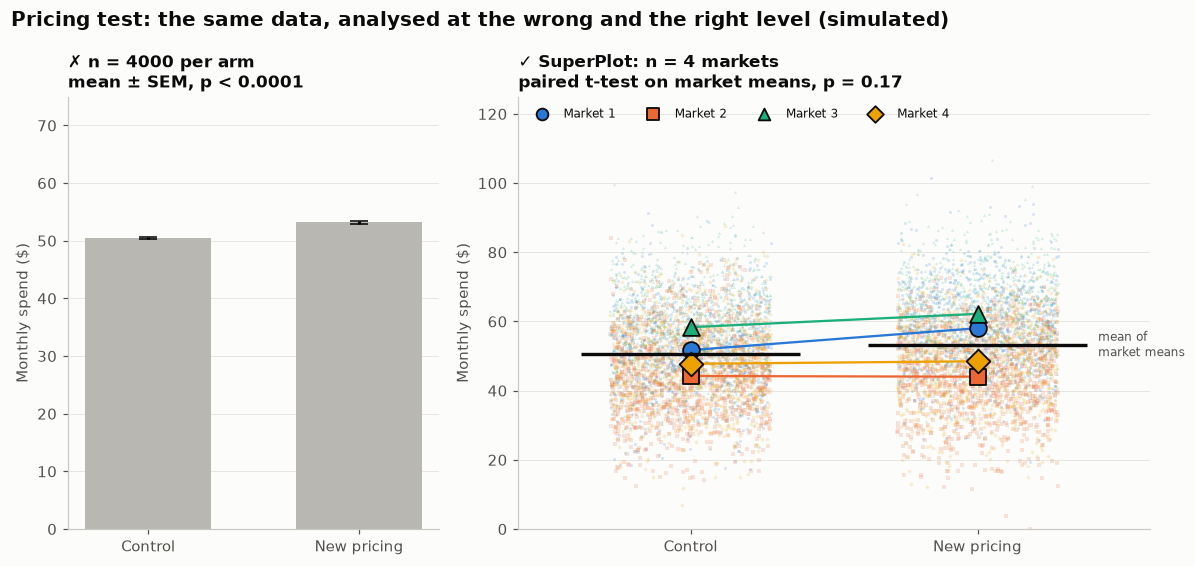

In [3]:
naive_p = stats.ttest_ind(*(df.loc[df["condition"] == c, "spend"] for c in conditions)).pvalue
paired_p = stats.ttest_rel(rep[conditions[1]], rep[conditions[0]]).pvalue
markers = ["o", "s", "^", "D"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1, 1.7]})

# The conventional chart: every customer counted as an independent n
m = df.groupby("condition")["spend"].agg(["mean", "sem"]).loc[conditions]
a1.bar(range(2), m["mean"], yerr=m["sem"], color=GRAY, width=0.6, capsize=6)
a1.set_xticks(range(2), conditions)
a1.set_ylim(0, 75)
a1.set_ylabel("Monthly spend ($)")
p_text = f"p = {naive_p:.4f}" if naive_p >= 1e-4 else "p < 0.0001"
a1.set_title(f"✗ n = {len(df) // 2} per arm\nmean ± SEM, {p_text}", fontsize=11)
a1.grid(axis="x", visible=False)

# The SuperPlot: customers colored by market, market means as big markers, test on market means
xr = np.random.default_rng(1)
for i, (mkt, mk) in enumerate(zip(markets, markers)):
    for x, cond in enumerate(conditions):
        vals = df.loc[(df["market"] == mkt) & (df["condition"] == cond), "spend"]
        a2.scatter(x + xr.uniform(-0.28, 0.28, len(vals)), vals, s=4, color=PALETTE[i], alpha=0.18,
                   marker=mk, linewidths=0)
    a2.plot([0, 1], rep.loc[mkt, conditions], color=PALETTE[i], linewidth=1.5, zorder=4)
    a2.scatter([0, 1], rep.loc[mkt, conditions], s=120, color=PALETTE[i], marker=mk,
               edgecolor="#0b0b0b", linewidth=1.2, zorder=5, label=mkt)
grand = rep.mean()
a2.hlines(grand.values, np.arange(2) - 0.38, np.arange(2) + 0.38, color="#0b0b0b", linewidth=2.2, zorder=6)
a2.set_xticks(range(2), conditions)
a2.set_xlim(-0.6, 1.6)
a2.set_ylabel("Monthly spend ($)")
a2.set_title(f"✓ SuperPlot: n = {len(markets)} markets\npaired t-test on market means, p = {paired_p:.2f}",
             fontsize=11)
a2.legend(loc="upper left", ncol=4, fontsize=8, markerscale=0.7, bbox_to_anchor=(0, 1.0))
a2.set_ylim(0, 125)
a2.grid(axis="x", visible=False)
a2.text(1.42, grand.iloc[1], "mean of\nmarket means", fontsize=8, va="center", color="#52514e")

fig.suptitle("Pricing test: the same data, analysed at the wrong and the right level (simulated)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

## How to read it

The left chart claims a highly significant lift, because it treats 4,000 customers per arm as 4,000 independent results. The SuperPlot shows why that is misleading: customers in the same market move together, and only four markets were tested. Two markets show a clear lift, one a small one and one none, so the replicate-level test is far from conclusive.

## Reference

This method comes from the research literature:

- Lord, S. J., Velle, K. B., Mullins, R. D. & Fritz-Laylin, L. K. (2020). SuperPlots: Communicating reproducibility and variability in cell biology. Journal of Cell Biology 219(6), e202001064. <https://doi.org/10.1083/jcb.202001064>

---
Standalone script: [`superplot.py`](superplot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)